# 05 · Step 1: morphology

The first shape change: random **growth of one label group into another**. It makes, for
example, the cortex thicker or thinner, or the ventricles larger, so the network does not learn
the exact anatomy of the few training subjects.

Code: `nxgen/online/morphology.py`. Config section: `morphology` (`pairs`, `n_iter`, `prob`).
Grid: HR (before the deformation).

In [2]:
from _setup import *
from nxgen.online import morphology as M
from nxgen.core.config import load_config
from nxgen.core.label_space import LabelSpace
import phantoms

## 1. The rule

For each configured pair `[a, b]`, with probability `prob`:

1. one of the two groups is chosen at random to **grow**, the other **shrinks**;
2. `n_iter` is drawn (layers of HR voxels);
3. `n_iter` times: every voxel of the shrinking group that touches (26-neighbourhood) the growing
   group takes a neighbouring growing label.

Voxels of other labels never change. When the growing group has several labels, a new voxel
copies the neighbouring growing label with the **largest index** (the max of a 3×3×3 max-pool),
so growth continues each structure into its neighbour.

A **group** is a tree node name (its whole subtree), a raw value, or a list of those
(notebook 02).

label space: [(0, 'background'), (2, 'wm'), (3, 'gm'), (24, 'csf'), (42, 'gm_part')]


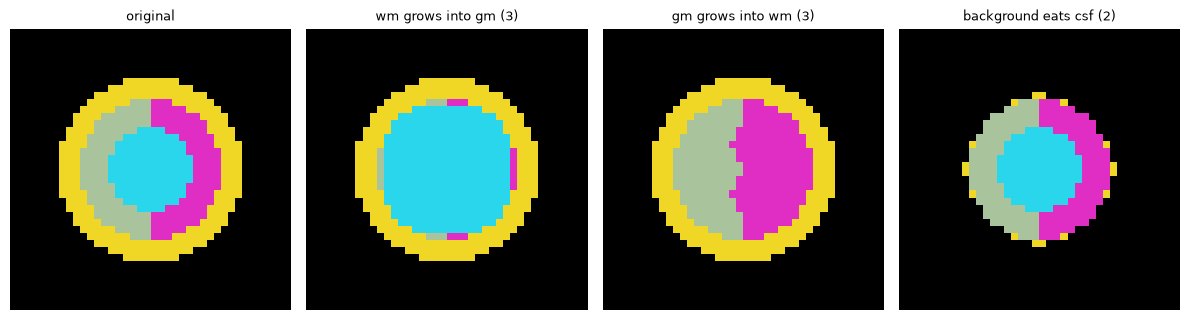

In [3]:
tree = phantoms.tree()
seg = phantoms.sphere_labels((40, 40, 40))
ls = LabelSpace.build(tree, set(np.unique(seg).tolist()))
lab = ls.lut(int(seg.max()))[torch.as_tensor(seg)]
print('label space:', list(zip(ls.values, ls.names)))

def op(grow, shrink, n):
    """One morphology operation, in the format of the plan."""
    return dict(grow=grow, shrink=shrink, n_iter=n,
                grow_idx=ls.resolve(grow, tree), shrink_idx=ls.resolve(shrink, tree))

out_wm = M.apply(lab, dict(ops=[op('wm', 'gm', 3)]), len(ls))
out_gm = M.apply(lab, dict(ops=[op('gm', 'wm', 3)]), len(ls))
out_bg = M.apply(lab, dict(ops=[op('background', 'csf', 2)]), len(ls))
show([lab, out_wm, out_gm, out_bg],
     ['original', 'wm grows into gm (3)', 'gm grows into wm (3)', 'background eats csf (2)'])

Note in the second image: WM grows into **both** GM labels (`gm` resolves to `gm` and its child
`gm_part`). In the third: both GM labels grow, each into its own side.

Which voxels changed, and from what to what:

In [4]:
changed = out_wm != lab
print('voxels changed:', int(changed.sum()))
print('their old labels:', sorted(set(ls.values[i] for i in lab[changed].tolist())),
      '-> new labels:', sorted(set(ls.values[i] for i in out_wm[changed].tolist())))
for v in ls.values:
    i = ls.index[v]
    print(f'  {ls.names[i]:10s} {int((lab == i).sum()):6d} -> {int((out_wm == i).sum()):6d} voxels')

voxels changed: 3120
their old labels: [3, 42] -> new labels: [2]
  background  54672 ->  54672 voxels
  wm            912 ->   4032 voxels
  gm           1656 ->     96 voxels
  csf          5104 ->   5104 voxels
  gm_part      1656 ->     96 voxels


## 2. Drawing the operations: `sample`

`sample(cfg, rng, label_space, tree)` returns the operations of one image (or `None`). For every
pair it always draws three numbers (apply?, which side grows, n_iter), so each pair's draw does
not depend on the previous pairs. Group names are resolved to indices here and stored in the
plan, so the plan is self-contained.

In [5]:
cfg = load_config(morphology=dict(pairs=[['gm', 'wm'], ['csf', 'gm'], ['background', 'csf']],
                                  n_iter={'randint': [1, 3]}, prob=0.7))['morphology']
for seed in range(3):
    print(f'seed {seed}:', M.sample(cfg, np.random.default_rng(seed), ls, tree))

    # Me quede aqui 

seed 0: {'ops': [{'grow': 'wm', 'shrink': 'gm', 'n_iter': 1, 'grow_idx': [1], 'shrink_idx': [2, 4]}, {'grow': 'csf', 'shrink': 'gm', 'n_iter': 1, 'grow_idx': [3], 'shrink_idx': [2, 4]}]}
seed 1: {'ops': [{'grow': 'gm', 'shrink': 'wm', 'n_iter': 1, 'grow_idx': [2, 4], 'shrink_idx': [1]}, {'grow': 'background', 'shrink': 'csf', 'n_iter': 1, 'grow_idx': [0], 'shrink_idx': [3]}]}
seed 2: {'ops': [{'grow': 'wm', 'shrink': 'gm', 'n_iter': 2, 'grow_idx': [1], 'shrink_idx': [2, 4]}, {'grow': 'csf', 'shrink': 'gm', 'n_iter': 3, 'grow_idx': [3], 'shrink_idx': [2, 4]}]}


## 3. Working on a crop: the halo

In patch mode (notebook 10) the generator does not run the morphology on the whole template,
only on the part a patch needs. Morphology is **local**: after `n` layers, a voxel depends only
on voxels at most `n` away. Operations are applied one after another, so the total reach is the
sum of the layers: `halo(params)`.

A crop extended by the halo gives, inside, **exactly** the full-volume result:

halo = 3 | crop result == full result: True
without the halo, voxels that differ: 78
full_roi_after == inner: True


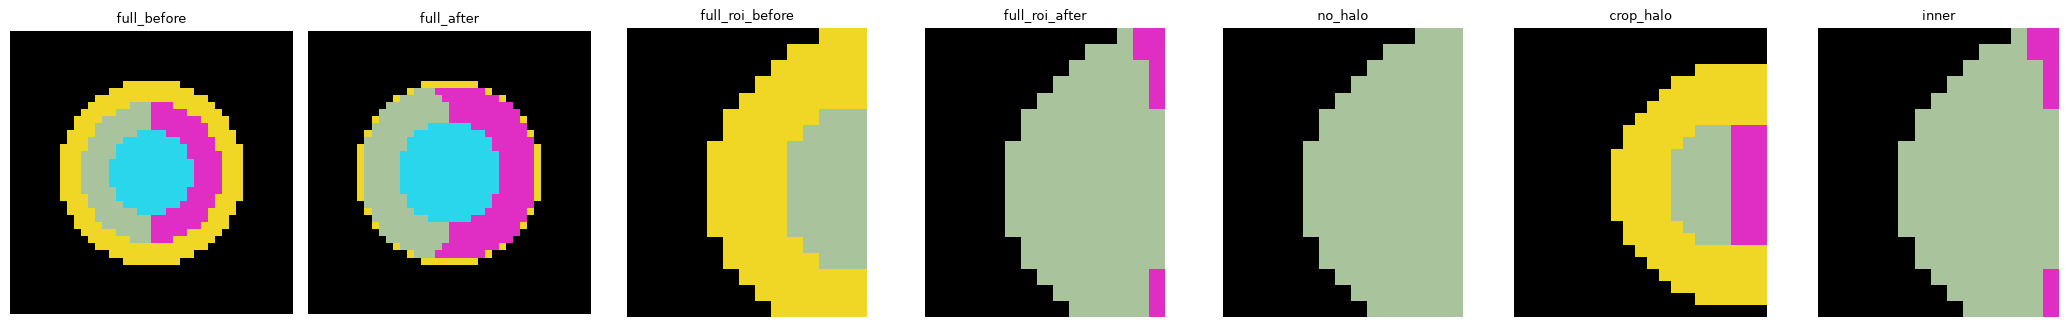

In [ ]:
params = dict(ops=[op('gm', 'csf', 2), op('wm', 'gm', 1)])
h = M.halo(params)
full = M.apply(lab, params, len(ls))
lo, hi = np.array([5, 12, 20]), np.array([20, 30, 36])
crop = lab[lo[0] - h:hi[0] + h, lo[1] - h:hi[1] + h, lo[2] - h:hi[2] + h]
inner = M.apply(crop, params, len(ls))[h:-h, h:-h, h:-h]
full_roi_before = lab[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
full_roi_after = full[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
print('halo =', h, '| crop result == full result:',
      torch.equal(inner, full_roi_after))
no_halo = M.apply(lab[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]], params, len(ls))
print('without the halo, voxels that differ:',
      int((no_halo != full_roi_after).sum()))

print("full_roi_after == inner:", torch.equal(full_roi_after, inner))
show([lab, full, full_roi_before, full_roi_after, no_halo, crop, inner],
     ['full_before', 'full_after', 'full_roi_before', 'full_roi_after', 'no_halo', 'crop_halo', 'inner'])

## 4. On the real template

The NextBrain config grows/shrinks six pairs of L1 groups (background ↔ cerebral GM,
GM ↔ WM, WM ↔ ventricles, ...) by 1-3 HR voxels (0.2-0.6 mm):

cerebral_gm_l1       grows into background_l1        by 3 voxels
background_l1        grows into cerebellar_gm_l1     by 1 voxels
cerebral_gm_l1       grows into cerebral_wm_l1       by 2 voxels
cerebellar_gm_l1     grows into cerebellar_wm_l1     by 3 voxels
cerebral_wm_l1       grows into csf_ventricles_l1    by 1 voxels
deep_gm_l1           grows into cerebral_wm_l1       by 1 voxels


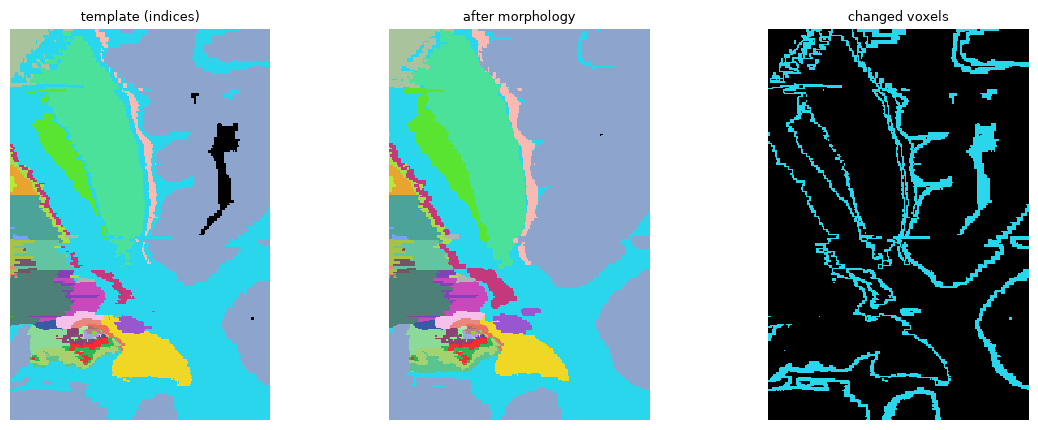

In [ ]:
from nxgen import Generator, Recorder

ensure_template()
gen = Generator([TEMPLATE], load_config(CONFIG, morphology={'prob': 1.0}), device=DEVICE)
plan = gen.sample_plan(4)
for o in plan['morphology']['ops']:
    print(f"{str(o['grow']):20s} grows into {str(o['shrink']):20s} by {o['n_iter']} voxels")

rec = Recorder(steps=['template_crop', 'morphology'])
gen.render(dict(plan, spatial=None), rec)
a, b = rec.steps['template_crop'], rec.steps['morphology']
z = a.shape[2] // 2
win = (slice(120, 320), slice(300, 600))
diff = (a != b).short()
show([a[:, :, z][win], b[:, :, z][win], diff[:, :, z][win]],
     ['template (indices)', 'after morphology', 'changed voxels'], labels=[True, True, True], size=4)

## 5. Notes

* Growth stops at the shrinking group: a pair never touches other labels. A pair with
  `background` moves the brain surface.
* Several pairs act one after the other in the configured order; a later pair sees the result
  of the earlier ones.
* The diagnostics `checks.vanished_labels` and `checks.adjacency_violations` (notebook 12) tell
  whether an operation removed a thin structure or created an implausible contact.
* Memory: on a full 0.2 mm template the step peaks at ~7 GB (several volume-sized temporaries);
  on a 160³ patch at ~2.4 GB.